In [1]:
# Cell 1 - Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid')
print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# Cell 2 - Load Data
df = pd.read_csv('../supply_chain_dataset1.csv', parse_dates=['Date'])
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
df.head()

Shape: (91250, 15)

Columns: ['Date', 'SKU_ID', 'Warehouse_ID', 'Supplier_ID', 'Region', 'Units_Sold', 'Inventory_Level', 'Supplier_Lead_Time_Days', 'Reorder_Point', 'Order_Quantity', 'Unit_Cost', 'Unit_Price', 'Promotion_Flag', 'Stockout_Flag', 'Demand_Forecast']


,Date,SKU_ID,Warehouse_ID,Supplier_ID,Region,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
0,2024-01-01,SKU_1,WH_1,SUP_8,West,10,592,14,379,0,13.95,20.48,0,0,8.52
1,2024-01-02,SKU_1,WH_1,SUP_8,West,17,575,14,379,0,13.95,20.48,0,0,18.63
2,2024-01-03,SKU_1,WH_1,SUP_8,North,35,540,14,379,0,13.95,20.48,1,0,39.62
3,2024-01-04,SKU_1,WH_1,SUP_8,South,24,516,14,379,0,13.95,20.48,0,0,19.43
4,2024-01-05,SKU_1,WH_1,SUP_8,West,21,495,14,379,0,13.95,20.48,0,0,18.70


In [3]:
# Cell 3 - Basic Info
print(df.info())
print("\nMissing Values:\n", df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91250 entries, 0 to 91249
Data columns (total 15 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Date                     91250 non-null  datetime64[ns]
 1   SKU_ID                   91250 non-null  object        
 2   Warehouse_ID             91250 non-null  object        
 3   Supplier_ID              91250 non-null  object        
 4   Region                   91250 non-null  object        
 5   Units_Sold               91250 non-null  int64         
 6   Inventory_Level          91250 non-null  int64         
 7   Supplier_Lead_Time_Days  91250 non-null  int64         
 8   Reorder_Point            91250 non-null  int64         
 9   Order_Quantity           91250 non-null  int64         
 10  Unit_Cost                91250 non-null  float64       
 11  Unit_Price               91250 non-null  float64       
 12  Promotion_Flag           91250 n

In [4]:
# Cell 4 - Descriptive Statistics
df.describe()

,Date,Units_Sold,Inventory_Level,Supplier_Lead_Time_Days,Reorder_Point,Order_Quantity,Unit_Cost,Unit_Price,Promotion_Flag,Stockout_Flag,Demand_Forecast
count,91250,91250.000000,91250.000000,91250.000000,91250.000000,91250.000000,91250.000000,91250.000000,91250.000000,91250.0,91250.000000
mean,2024-07-01 00:00:00,20.054564,471.522312,7.984000,300.068000,19.272493,12.203320,18.261800,0.101589,0.0,20.082033
min,2024-01-01 00:00:00,0.000000,168.000000,2.000000,201.000000,0.000000,5.020000,6.950000,0.000000,0.0,0.000000
25%,2024-04-01 00:00:00,13.000000,370.000000,4.000000,252.000000,0.000000,8.180000,12.000000,0.000000,0.0,12.950000
50%,2024-07-01 00:00:00,20.000000,461.000000,8.000000,300.000000,0.000000,11.990000,18.180000,0.000000,0.0,19.950000
75%,2024-09-30 00:00:00,27.000000,564.000000,11.000000,346.000000,0.000000,16.320000,23.390000,0.000000,0.0,26.930000
max,2024-12-30 00:00:00,59.000000,990.000000,14.000000,398.000000,499.000000,19.760000,35.100000,1.000000,0.0,61.420000
std,NaN,9.068602,133.488002,3.907929,54.879945,82.340831,4.574982,7.121136,0.302109,0.0,9.503955


In [5]:
# Cell 5 - Categorical Exploration
for col in ['SKU_ID', 'Warehouse_ID', 'Supplier_ID', 'Region']:
    print(f"\n{col}: {df[col].nunique()} unique values")
    print(df[col].value_counts().head())


SKU_ID: 50 unique values
SKU_ID
SKU_1    1825
SKU_2    1825
SKU_3    1825
SKU_4    1825
SKU_5    1825
Name: count, dtype: int64

Warehouse_ID: 5 unique values
Warehouse_ID
WH_1    18250
WH_2    18250
WH_3    18250
WH_4    18250
WH_5    18250
Name: count, dtype: int64

Supplier_ID: 10 unique values
Supplier_ID
SUP_7     12410
SUP_8     10220
SUP_1     10220
SUP_10     9855
SUP_2      9490
Name: count, dtype: int64

Region: 4 unique values
Region
North    22974
East     22934
South    22720
West     22622
Name: count, dtype: int64


In [6]:
# Cell 6 - Date Range
print("Date range:", df['Date'].min(), "to", df['Date'].max())
print("Total days:", (df['Date'].max() - df['Date'].min()).days)
print("Total records:", len(df))

Date range: 2024-01-01 00:00:00 to 2024-12-30 00:00:00
Total days: 364
Total records: 91250


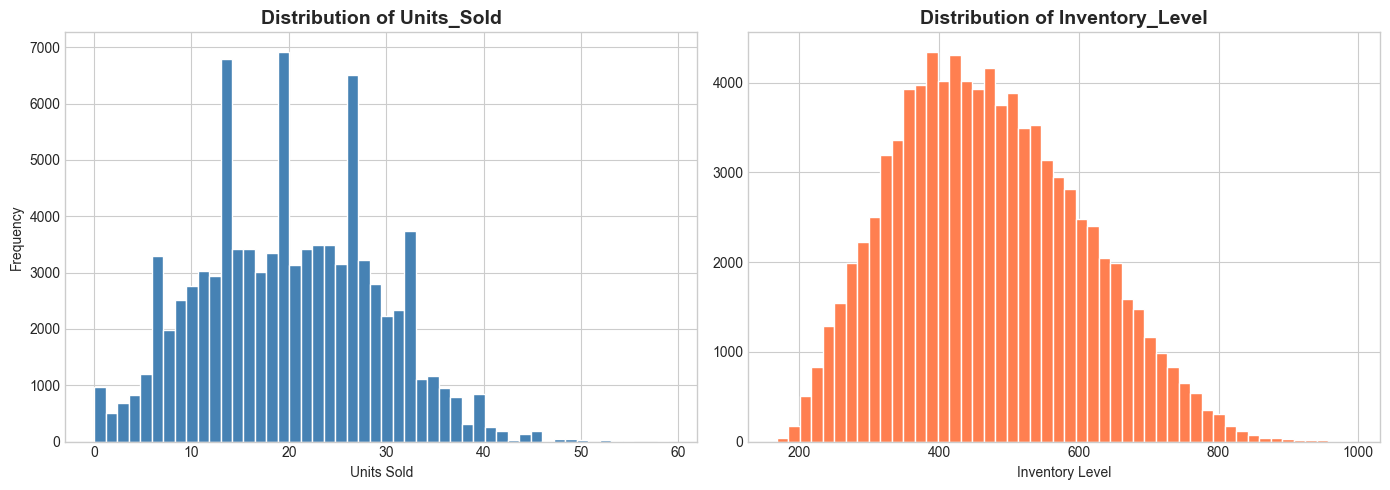

In [7]:
# Cell 7 - Target Variable Distributions
import os
os.makedirs('../outputs/plots', exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df['Units_Sold'].hist(bins=50, ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Distribution of Units_Sold', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Units Sold')
axes[0].set_ylabel('Frequency')
df['Inventory_Level'].hist(bins=50, ax=axes[1], color='coral', edgecolor='white')
axes[1].set_title('Distribution of Inventory_Level', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Inventory Level')
plt.tight_layout()
plt.savefig('../outputs/plots/01_target_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

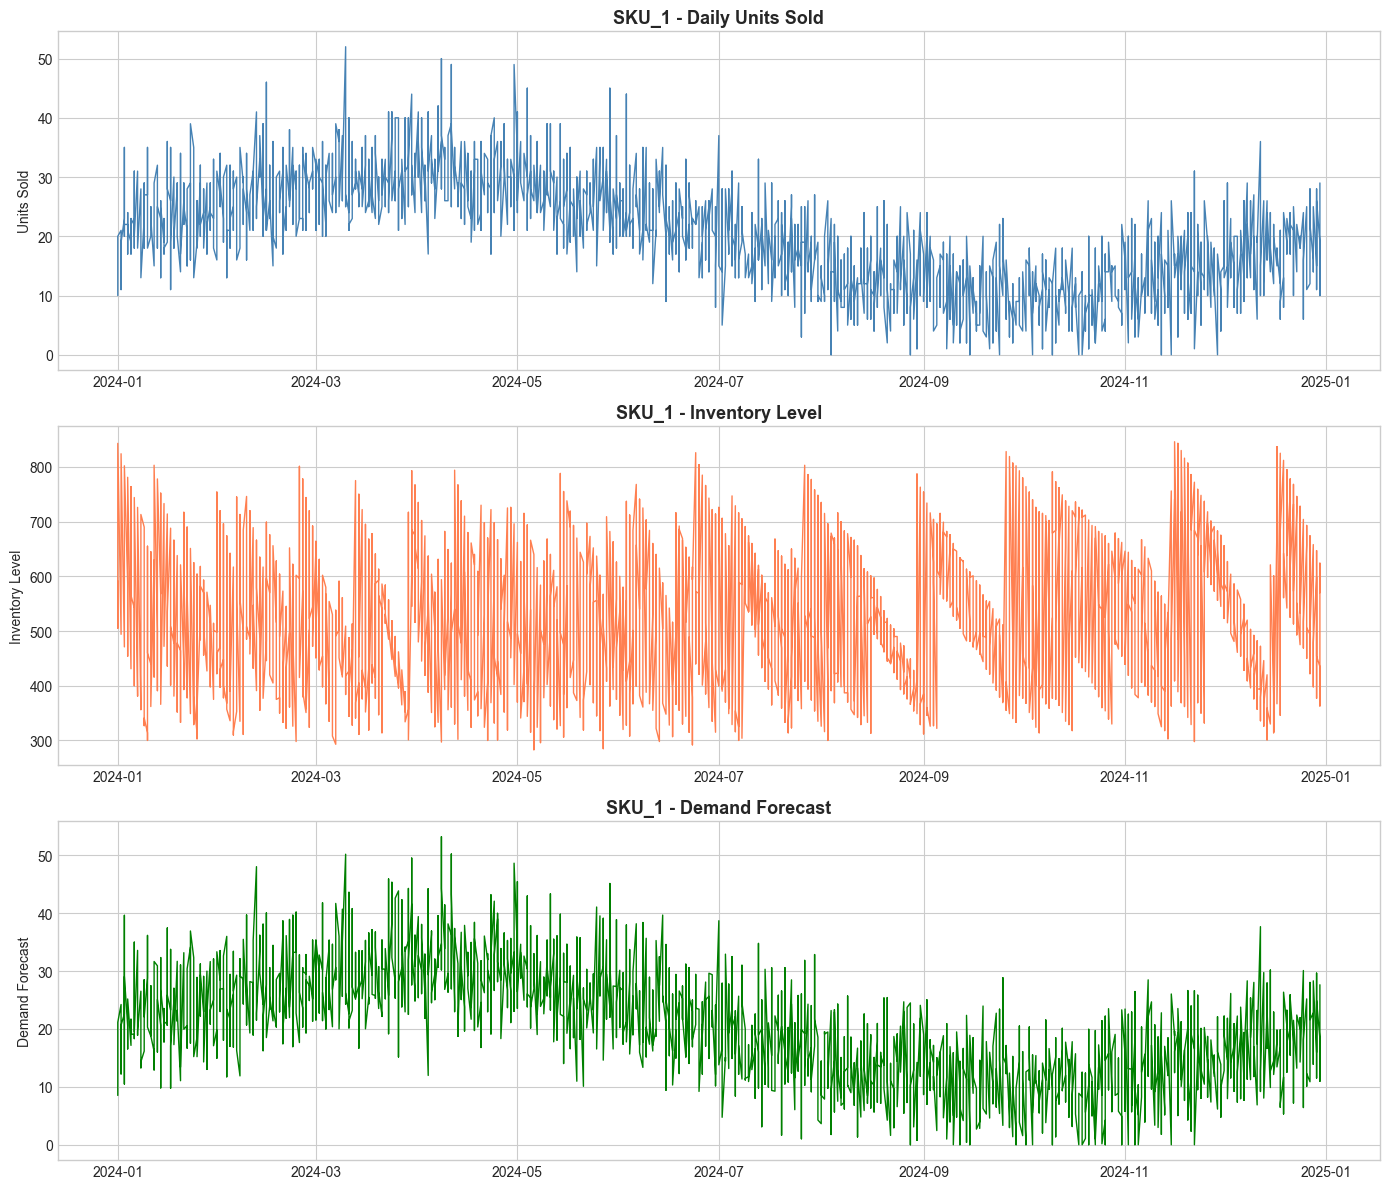

In [8]:
# Cell 8 - Time Series Plot for Sample SKU
sample_sku = df[df['SKU_ID'] == 'SKU_1'].sort_values('Date')
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
axes[0].plot(sample_sku['Date'], sample_sku['Units_Sold'], color='steelblue', linewidth=1)
axes[0].set_title('SKU_1 - Daily Units Sold', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Units Sold')
axes[1].plot(sample_sku['Date'], sample_sku['Inventory_Level'], color='coral', linewidth=1)
axes[1].set_title('SKU_1 - Inventory Level', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Inventory Level')
axes[2].plot(sample_sku['Date'], sample_sku['Demand_Forecast'], color='green', linewidth=1)
axes[2].set_title('SKU_1 - Demand Forecast', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Demand Forecast')
plt.tight_layout()
plt.savefig('../outputs/plots/01_sku1_timeseries.png', dpi=150, bbox_inches='tight')
plt.show()

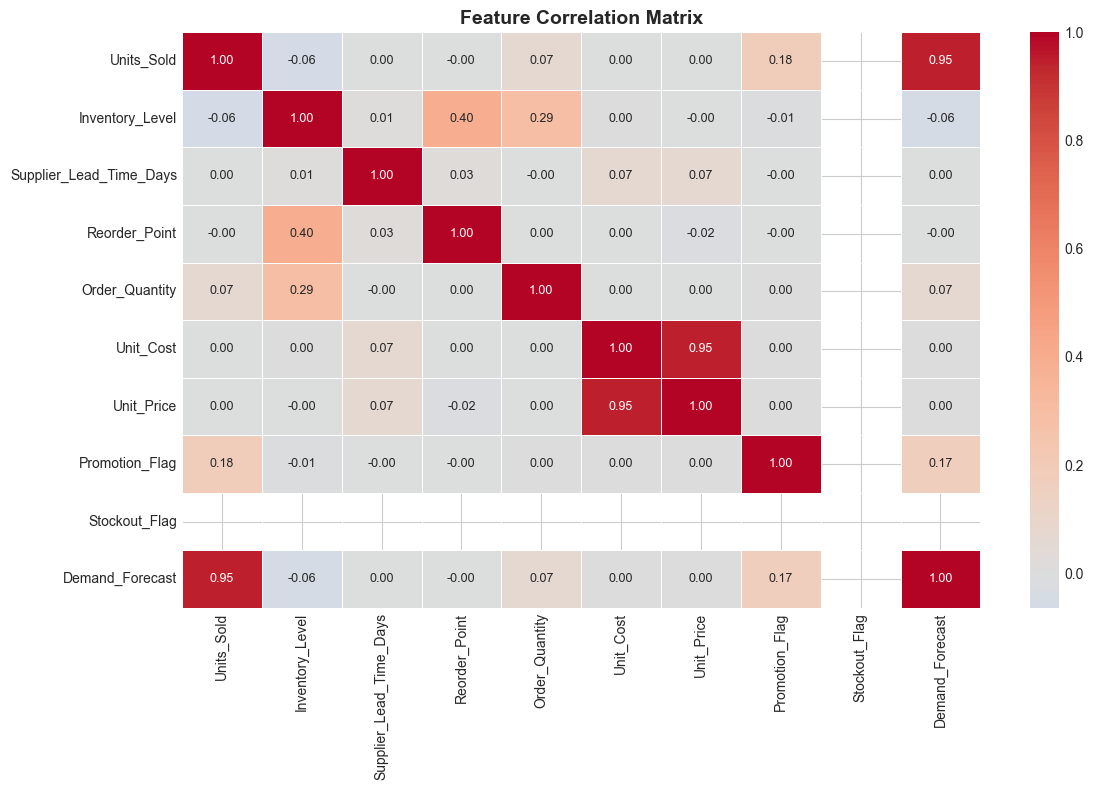

In [9]:
# Cell 9 - Correlation Heatmap
numeric_df = df.select_dtypes(include=[np.number])
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', cmap='coolwarm',
            center=0, ax=ax, linewidths=0.5, annot_kws={'size': 9})
ax.set_title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/01_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

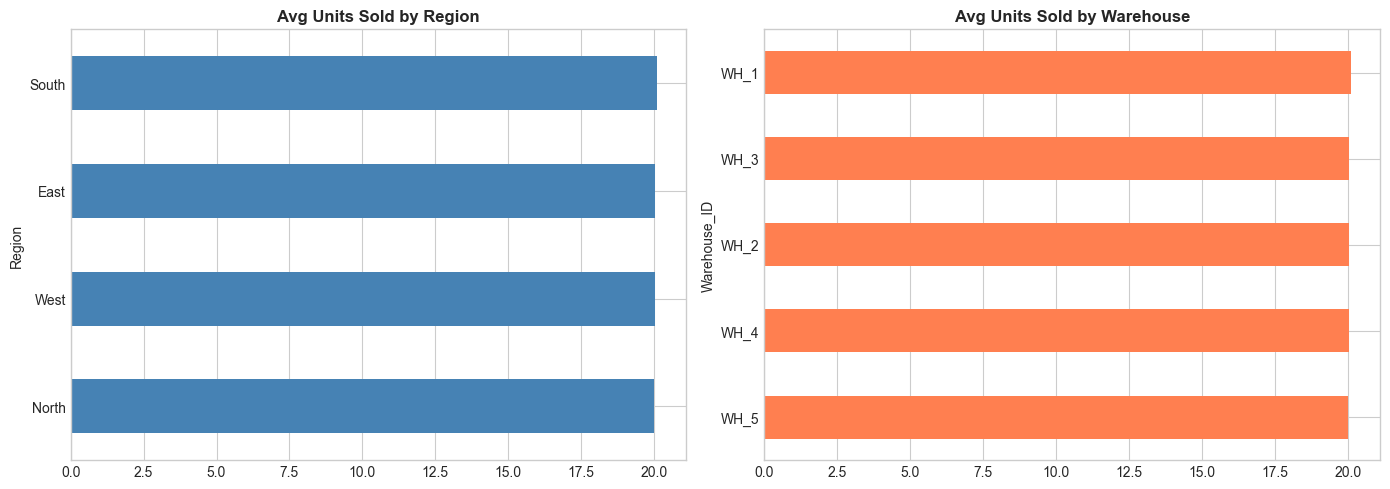

In [10]:
# Cell 10 - Units Sold by Region & Warehouse
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
df.groupby('Region')['Units_Sold'].mean().sort_values().plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Avg Units Sold by Region', fontweight='bold')
df.groupby('Warehouse_ID')['Units_Sold'].mean().sort_values().plot(kind='barh', ax=axes[1], color='coral')
axes[1].set_title('Avg Units Sold by Warehouse', fontweight='bold')
plt.tight_layout()
plt.savefig('../outputs/plots/01_sales_by_groups.png', dpi=150, bbox_inches='tight')
plt.show()

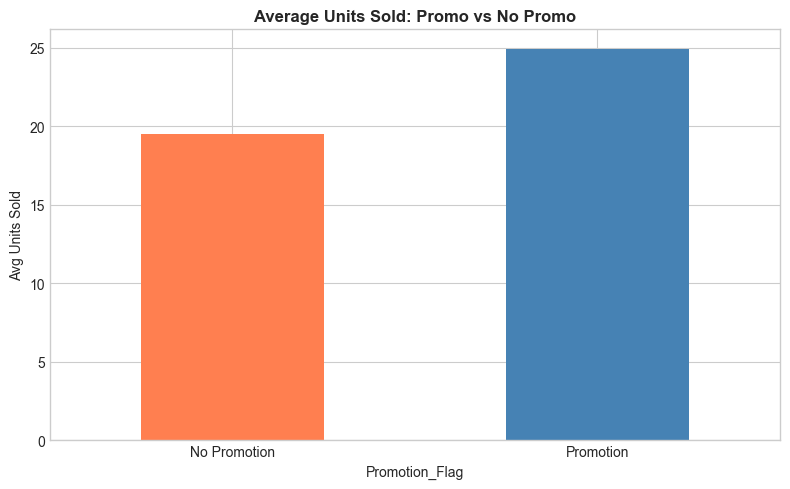

In [11]:
# Cell 11 - Promotion Impact
fig, ax = plt.subplots(figsize=(8, 5))
df.groupby('Promotion_Flag')['Units_Sold'].mean().plot(
    kind='bar', ax=ax, color=['coral', 'steelblue'], rot=0)
ax.set_title('Average Units Sold: Promo vs No Promo', fontweight='bold')
ax.set_xticklabels(['No Promotion', 'Promotion'])
ax.set_ylabel('Avg Units Sold')
plt.tight_layout()
plt.savefig('../outputs/plots/01_promotion_impact.png', dpi=150, bbox_inches='tight')
plt.show()

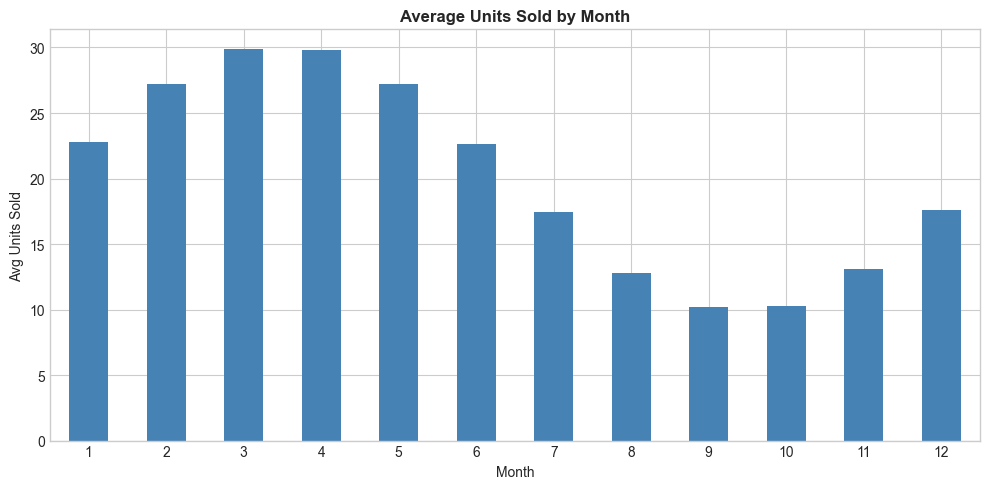


✅ Data Exploration Complete!


In [12]:
# Cell 12 - Monthly Aggregation
df['Month'] = df['Date'].dt.month
df['DayOfWeek'] = df['Date'].dt.dayofweek
monthly = df.groupby('Month')['Units_Sold'].mean()
fig, ax = plt.subplots(figsize=(10, 5))
monthly.plot(kind='bar', ax=ax, color='steelblue', rot=0)
ax.set_title('Average Units Sold by Month', fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Avg Units Sold')
plt.tight_layout()
plt.savefig('../outputs/plots/01_monthly_avg.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ Data Exploration Complete!")